# Fixed Income Risk Dashboard
### Task 02 · Daily Risk Attribution & Historical VaR Walk

**Rates Desk Analytics**  ·  Python / NumPy / pandas  ·  C# / ClosedXML  ·  Excel Reporting  
**Dataset:** simulated government bond desk  ·  **Report window:** 2023–2024  ·  **Valuation:** EOD

> **The trading-desk question:** Yesterday's risk report shows a different VaR from today's. How much came from aging, market repricing, rolling historical scenarios, and booked trades?

| Reporting coverage | Year-end Net DV01 | Year-end 1-day 99% VaR | 2024 VaR change |
|:--|--:|--:|--:|
| **518 mornings** | **+$47,234 / bp** | **$939,306** | **−$497,829** |

This notebook builds and validates a **sequential, fully reconciled risk walk**. The accompanying C# reporting layer turns the model into a **date-selectable Excel investigation tool**—not a live trading or production limit engine.

**Navigation**  
[01 · Problem & Scope](#01--problem--scope) · [02 · Market & Book Data](#02--market--book-data) · [03 · Pricing Engine](#03--pricing-engine) · [04 · DV01 Walk](#04--key-rate-dv01-walk) · [05 · VaR Walk](#05--historical-var-walk) · [06 · Results](#06--2024-attribution-results) · [07 · Investigations](#07--investigation-cases) · [08 · Controls](#08--validation--controls) · [09 · Excel Delivery](#09--excel-reporting-delivery)

---

*Adapted and extended from the [RiskHub Fixed Income Risk Dashboard Python Lab](https://riskhub.org/python-labs/fixed-income-risk-dashboard). Educational simulated data; no real desk or investment recommendation is implied.*


## 01 · Problem & Scope

### Why a risk walk matters

A single **closing VaR** figure does not explain **what changed**. On a rates desk, yesterday's positions can become riskier or less risky even if no trade is booked. The valuation date advances, the yield curve changes, and the Historical Simulation estimation window rolls forward.

| Driver | What changes? | Risk-manager question |
|:--|:--|:--|
| **Time / Aging** | Valuation date advances; the curve and positions stay fixed | Did duration naturally decay? |
| **Market / Curve** | Yesterday's positions are revalued using today's curve | Did rates or curve shape move the exposure? |
| **Window Roll** | A historical curve shock leaves the 500-day sample and another enters | Did the tail scenario distribution change? |
| **Trades / Amendments** | Closing positions reflect the current blotter and ticket corrections | Which booking altered the desk's risk? |

**Deliverables:** a daily DV01 walk, a five-state Historical VaR bridge, year/tenor-level attribution, reconciliation controls, case studies, and an interactive Excel report.

**Boundary:** this task **explains movements in risk measures**. Task 3 separately analyzes *reported vs. modeled P&L*; Tasks 4–5 investigate feed / booking incidents and alerting policies.


## 02 · Market & Book Data

The model covers **19 fixed-coupon government bond instruments**, a simulated trade blotter, and **11 continuously compounded zero-rate vertices** from 3 months to 30 years.

| Input | Interpretation | Unit |
|:--|:--|:--|
| `Z_3M` … `Z_30Y` | Daily zero-coupon yield curve | Percent (%) |
| `BONDS` | Annual coupon rate and contractual maturity | % and date |
| `BLOTTER` | Ticket ID, booked/traded dates, bond, signed face | USD millions |
| `PNL_REPORTED` | External reported desk P&L, reserved for subsequent P&L analysis | USD |
| `VAR_DAYS = 500` | Rolling Historical Simulation sample | Business-day observations |
| `VAR_K = 5` | Fifth-worst scenario out of 500: empirical 99% VaR | Order statistic |

> **Booking convention:** when a trade ticket is amended, the latest *booked* entry **replaces** its prior face amount; it is not an additional trade. This matters when isolating the Trades / Amendments contribution.

**Running this project locally:** place the supplied/authorized input file at `DataSource/rates_desk_feed.csv` relative to the project root. The source dataset is intentionally not bundled in this GitHub-ready notebook; please review its redistribution rights before publishing it.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
from pathlib import Path

# Choose the project root from RAD_RISK_ROOT or the Jupyter working directory.
PROJECT_ROOT = Path(os.environ.get("RAD_RISK_ROOT", Path.cwd())).expanduser()
DATA_FILE = PROJECT_ROOT / "DataSource" / "rates_desk_feed.csv"
if not DATA_FILE.is_file():
    raise FileNotFoundError(
        f"Missing input: {DATA_FILE}\n"
        "Set RAD_RISK_ROOT to the project folder or open Jupyter from it."
    )

df = pd.read_csv(
    DATA_FILE,
    parse_dates=['date'],
    index_col='date'
)
DATES = df.index                                   # business days 2020-12-31 .. 2024-12-31
LAB = [c[2:] for c in df.columns if c.startswith('Z_')]          # '3M', '6M', ..., '30Y'
TEN = np.array([0.25, 0.5, 1, 2, 3, 5, 7, 10, 15, 20, 30])       # years of the Z_ columns: the curve's VERTICES
Z = df[['Z_' + x for x in LAB]].to_numpy()         # the curve FEED as received: zero yields, %, continuously compounded
PNL = df['PNL_REPORTED'].to_numpy()                # the P&L system's daily desk P&L, USD (NaN before 2023-01-03)
REP = np.where(DATES >= '2023-01-03')[0]           # report mornings: every day with a reported P&L
BONDS = {   # bond: (coupon % a year, paid twice a year, maturity date)
    'GOV_23': (0.875, '2023-09-30'), 'GOV_24': (1.500, '2024-05-15'), 'GOV_25': (2.750, '2025-08-15'),
    'GOV_26': (4.125, '2026-06-15'), 'GOV_27': (3.250, '2027-11-15'), 'GOV_27B': (4.500, '2027-05-15'),
    'GOV_28': (4.000, '2028-05-15'), 'GOV_29': (3.750, '2029-02-15'), 'GOV_29B': (4.000, '2029-08-15'),
    'GOV_30': (4.000, '2030-02-15'), 'GOV_31': (4.125, '2031-08-15'), 'GOV_32': (2.875, '2032-05-15'),
    'GOV_33': (3.500, '2033-02-15'), 'GOV_34': (4.250, '2034-02-15'), 'GOV_37': (4.000, '2037-11-15'),
    'GOV_42': (3.250, '2042-08-15'), 'GOV_44': (4.375, '2044-02-15'), 'GOV_52': (3.000, '2052-08-15'),
    'GOV_53': (4.125, '2053-08-15'),
}
IDS = list(BONDS)
BLOTTER = [   # the risk system's trade blotter: (ticket, booked, traded, bond, face USD m: + bought / - sold)
    ('T001', '2022-12-30', '2022-12-30', 'GOV_23', 70), ('T002', '2022-12-30', '2022-12-30', 'GOV_24', 60),
    ('T003', '2022-12-30', '2022-12-30', 'GOV_25', 80), ('T004', '2022-12-30', '2022-12-30', 'GOV_27', 150),
    ('T005', '2022-12-30', '2022-12-30', 'GOV_29', 90), ('T006', '2022-12-30', '2022-12-30', 'GOV_32', -120),
    ('T007', '2022-12-30', '2022-12-30', 'GOV_33', -60), ('T008', '2022-12-30', '2022-12-30', 'GOV_37', 40),
    ('T009', '2022-12-30', '2022-12-30', 'GOV_42', -50), ('T010', '2022-12-30', '2022-12-30', 'GOV_52', 35),
    ('T011', '2023-02-14', '2023-02-14', 'GOV_26', 50), ('T012', '2023-04-20', '2023-04-20', 'GOV_32', 40),
    ('T013', '2023-06-07', '2023-06-07', 'GOV_30', 70), ('T014', '2023-08-23', '2023-08-23', 'GOV_44', -30),
    ('T015', '2023-10-11', '2023-10-11', 'GOV_27', -50), ('T016', '2023-11-29', '2023-11-29', 'GOV_53', 25),
    ('T017', '2024-01-17', '2024-01-17', 'GOV_25', -40), ('T018', '2024-02-21', '2024-02-21', 'GOV_30', 30),
    ('T019', '2024-04-10', '2024-04-10', 'GOV_34', 50), ('T019', '2024-04-16', '2024-04-10', 'GOV_34', -50),
    ('T020', '2024-05-22', '2024-05-22', 'GOV_42', 20),
    ('T021', '2024-06-12', '2024-06-12', 'GOV_27B', 40), ('T021', '2024-06-26', '2024-06-12', 'GOV_27B', 4),
    ('T022', '2024-08-07', '2024-08-07', 'GOV_44', 15),
    ('T026', '2024-08-21', '2024-08-21', 'GOV_28', 260), ('T027', '2024-08-21', '2024-08-21', 'GOV_31', -170),
    ('T023', '2024-09-12', '2024-09-09', 'GOV_29B', 8),
    ('T025', '2024-12-04', '2024-12-04', 'GOV_26', -20),
]   # a ticket that appears twice was AMENDED: its later row replaces the earlier one from that booked date
VAR_DAYS, VAR_K = 500, 5    # 1-day 99% HS VaR: the 5th worst of the last 500 daily curve moves (1% of 500)


## 03 · Pricing Engine

Before decomposing portfolio risk, every historical close must reproduce the same bond book and risk sensitivities used in Task 1.

### 03.1 Bond cash flows & zero-rate interpolation

For bond cash flows $CF_i$ paid at times $t_i$, the present value per 100 face is:

$$
PV = \sum_{i} CF_i\, e^{-z(t_i)t_i},
\qquad z(t_i) = \sum_{k=1}^{11} w_{ik} z_k.
$$

Here the continuously compounded rate $z(t_i)$ is represented in **decimal** form in the formula (the feed stores percent). Curve interpolation is linear within the vertices, with flat extrapolation beyond the endpoints.

The bond-level **Key-Rate DV01** is the USD change for a **1bp decline** at a particular curve vertex. Summing those sensitivities over live positions gives the desk's 11-element exposure ladder.


In [2]:
def cash_flows(bond):
    """ the bond's payment dates after the data starts (every 6 months back from maturity, unadjusted)
    and its payments per 100 face: coupon / 2 on each date, + 100 at maturity."""
    cpn, mat = BONDS[bond]
    mat = pd.Timestamp(mat)
    dates = pd.DatetimeIndex([mat - pd.DateOffset(months=6 * k) for k in range(80)][::-1])
    dates = dates[dates > DATES[0]]
    cf = np.full(len(dates), cpn / 2)
    cf[-1] += 100.0
    return dates, cf


def interp_weights(tau):
    """ weights W (shape tau.shape + (11,)) with W @ curve = the zero rate at each tau, linear between
    vertices and flat beyond the first and last. Each row has at most two non-zero weights, summing to 1."""
    tc = np.clip(tau, TEN[0], TEN[-1])
    j = np.clip(np.searchsorted(TEN, tc, side='right') - 1, 0, len(TEN) - 2)
    a = (tc - TEN[j]) / (TEN[j + 1] - TEN[j])
    W = np.zeros(np.shape(tau) + (len(TEN),))
    np.put_along_axis(W, j[..., None], (1 - a)[..., None], axis=-1)
    W2 = np.zeros_like(W)
    np.put_along_axis(W2, (j + 1)[..., None], a[..., None], axis=-1)
    return W + W2


### 03.2 Book reconstruction & daily sensitivity history

`positions_history()` expands the amended blotter into a **days × bonds** position matrix. `history()` computes each bond's current-curve price and ladder (`V`, `K`), plus the **aged-on-yesterday's-curve** equivalents (`VA`, `KA`) used to isolate time decay.

$$
\text{Position value (USD)} = \text{Face (USD millions)} \times 10^4 \times \text{Price per 100}.
$$

The same scaling converts per-100-face Key-Rate DV01 into portfolio **USD/bp**.


In [3]:
def positions_history(blotter=BLOTTER):
    """(Task 1's book_on, for every day at once): the position in each bond (days x bonds, USD m
    face) at each close. Each blotter row changes its ticket's face from that row's booked date onwards."""
    b = pd.DataFrame(blotter, columns=['ticket', 'booked', 'traded', 'bond', 'face'])
    step = b['face'] - b.groupby('ticket')['face'].shift(1).fillna(0)
    Q = np.zeros((len(DATES), len(IDS)))
    for r, bond, s in zip(DATES.searchsorted(pd.to_datetime(b['booked'])), b['bond'], step):
        Q[r:, IDS.index(bond)] += s
    return Q


def history(curves):
    """(Task 1's price_and_ladder, for every day and bond at once). Per 100 face, rows = days, columns =
    bonds: V = value off curve t on day t; VA = value off curve t-1 on day t (the bond one day OLDER, on YESTERDAY's
    curve); K, KA = the key-rate ladders of the same two (days x bonds x 11); CASH = what the bond paid in (t-1, t]."""
    prev = np.vstack([curves[:1], curves[:-1]])
    out = {k: [] for k in ('V', 'VA', 'K', 'KA', 'CASH')}
    for bond in IDS:
        dates, cf = cash_flows(bond)
        tau = (dates.values[None, :] - DATES.values[:, None]) / np.timedelta64(1, 'D') / 365.0
        live = tau > 0
        W = interp_weights(np.where(live, tau, 1.0))
        for name, C in (('', curves), ('A', prev)):
            dfac = np.where(live, np.exp(-np.einsum('nmk,nk->nm', W, C) / 100 * tau), 0.0)
            out['V' + name].append(dfac @ cf)
            out['K' + name].append(np.einsum('nm,nmk->nk', dfac * cf * tau, W) * 1e-4)
        paid = (dates.values[None, :] > DATES.values[:-1, None]) & (dates.values[None, :] <= DATES.values[1:, None])
        out['CASH'].append(np.concatenate([[0.0], paid.astype(float) @ cf]))
    return {k: np.stack(v, axis=1) for k, v in out.items()}


UNIT = 1e4    # USD per (USD m face x price per 100): a position's USD value = face x UNIT x value per 100


## 04 · Key-Rate DV01 Walk

### Four states · three attribution drivers

| State | Positions | Valuation setup | Interpretation |
|:--|:--|:--|:--|
| **L0** | Yesterday | Yesterday's date and curve | Opening reported ladder |
| **L1** | Yesterday | Today's date, yesterday's curve | Add **Time / Aging** |
| **L2** | Yesterday | Today's date and curve | Add **Market / Curve** |
| **L3** | Today | Today's date and curve | Add **Trades / Amendments** |

$$
\begin{aligned}
\Delta L_{\text{time}} &= L_1-L_0 \\
\Delta L_{\text{market}} &= L_2-L_1 \\
\Delta L_{\text{trades}} &= L_3-L_2
\end{aligned}
$$

**Reconciliation:** $\;L_3-L_0 = \Delta L_{\text{time}} + \Delta L_{\text{market}} + \Delta L_{\text{trades}}\;$ at **every curve vertex**, not only at the Net DV01 level.

Implementation: use vectorized `np.einsum` to aggregate the **bond × tenor** exposures into four **day × tenor** portfolios.


In [4]:
def ladder_states(Q, K, KA):
    """ The four ladders of every morning's walk, each (days x 11) in USD per bp. Q = positions in USD units
    (days x bonds); K, KA from history(). For morning t:
      L0 = yesterday's report:     Q[t-1] with K[t-1]
      L1 = + one day older:        Q[t-1] with KA[t]   (same positions, aged a day, still on yesterday's curve)
      L2 = + today's curve:        Q[t-1] with K[t]
      L3 = + today's trades:       Q[t]   with K[t]    (= today's report)
    Row 0 has no yesterday: use row 0 as its own t-1. Ladder of a book = sum over bonds of Q x K (np.einsum)."""
    q_prev = np.vstack([Q[:1], Q[:-1]])
    k_prev = np.vstack([K[:1], K[:-1]])

    L0 = np.einsum('nb,nbk->nk', q_prev, k_prev)
    L1 = np.einsum('nb,nbk->nk', q_prev, KA)
    L2 = np.einsum('nb,nbk->nk', q_prev, K)
    L3 = np.einsum('nb,nbk->nk', Q, K)

    return L0, L1, L2, L3


## 05 · Historical VaR Walk

### From the DV01 ladder to 500 scenario P&Ls

For each observed historical yield change $\Delta y_{s,k}$ in **basis points**:

$$
\widehat{P\&L}_s = -\sum_{k=1}^{11} L_k\,\Delta y_{s,k}.
$$

The model sorts 500 estimated scenario P&Ls and defines **1-day 99% Historical Simulation VaR** as the negative of the **fifth-worst** outcome.

### Five VaR states · four risk drivers

| State | Portfolio ladder | Shock window | Driver added |
|:--|:--|:--|:--|
| **V0** | L0 | Previous 500 observations | Opening VaR |
| **V1** | L1 | Previous 500 observations | Time / Aging |
| **V2** | L2 | Previous 500 observations | Market / Curve |
| **V3** | L2 | Current 500 observations | Historical Window Roll |
| **V4** | L3 | Current 500 observations | Trades / Amendments |

$$
\underbrace{V_4-V_0}_{\text{Total VaR change}}
= (V_1-V_0)+(V_2-V_1)+(V_3-V_2)+(V_4-V_3).
$$

> **Attribution convention:** these are *sequential counterfactual re-estimations*, not independent additive risk factors. Historical VaR is an order statistic; the attributed amounts can change if the state ordering is changed.


In [5]:
def var(ladder, window):
    """ 1-day 99% HS VaR (USD) of one ladder over a window of daily moves (rows, bp): minus the VAR_K-th worst
    of -window @ ladder."""
    pnl = -window @ ladder
    return -float(np.partition(pnl, VAR_K - 1)[VAR_K - 1])



def var_states(L, moves, t):
    """ The five VaRs of morning t. L = (L0, L1, L2, L3) from ladder_states; moves[s] = the curve move INTO day s
    (bp). Yesterday's window = moves[t - VAR_DAYS : t]; today's window = moves[t - VAR_DAYS + 1 : t + 1].
      V0 = L0 on yesterday's window     V1 = L1 on yesterday's     V2 = L2 on yesterday's
      V3 = L2 on TODAY's window         V4 = L3 on today's window  (= today's report)"""
    yesterday = moves[t - VAR_DAYS:t]
    today = moves[t - VAR_DAYS + 1:t + 1]

    L0, L1, L2, L3 = L

    return (
        var(L0[t], yesterday),
        var(L1[t], yesterday),
        var(L2[t], yesterday),
        var(L2[t], today),
        var(L3[t], today),
    )


## 06 · 2024 Attribution Results

### Calculate daily opening risk, contributions and closing risk

The following cell applies the four ladders and five VaR states across **518 reporting mornings (258 in 2023; 260 in 2024)**. All attribution tables are calculated directly from the modeled positions and yield curves—**not manually-entered Excel figures**.


In [6]:
# Build daily close / aged / market / traded risk ladders and VaR states.
H = history(Z)
Q = positions_history() * UNIT
moves = np.vstack([np.zeros((1, len(LAB))), np.diff(Z, axis=0) * 100])

L = ladder_states(Q, H["K"], H["KA"])
L0, L1, L2, L3 = L
V = np.array([var_states(L, moves, t) for t in REP])

dv = pd.DataFrame(
    {
        "time": (L1 - L0).sum(axis=1),
        "market": (L2 - L1).sum(axis=1),
        "trades": (L3 - L2).sum(axis=1),
    },
    index=DATES,
)
dv["start"], dv["end"] = L0.sum(axis=1), L3.sum(axis=1)
dv = dv.iloc[REP]

vr = pd.DataFrame(
    {
        "start": V[:, 0],
        "time": V[:, 1] - V[:, 0],
        "market": V[:, 2] - V[:, 1],
        "window": V[:, 3] - V[:, 2],
        "trades": V[:, 4] - V[:, 3],
        "end": V[:, 4],
    },
    index=DATES[REP],
)

print(f"Report mornings: {len(dv):,}  |  Date range: {dv.index.min():%Y-%m-%d} to {dv.index.max():%Y-%m-%d}")
print(f"Closing Net DV01: {dv['end'].iloc[-1]:+,.0f} USD/bp")
print(f"Closing 99% VaR: ${vr['end'].iloc[-1]:,.0f}")


Report mornings: 518  |  Date range: 2023-01-03 to 2024-12-31
Closing Net DV01: +47,234 USD/bp
Closing 99% VaR: $939,306


### 06.1 Year-end comparison and yearly driver breakdown

The desk's closing 99% VaR fell from approximately **$1.437m** to **$939k** across the 2024 reporting year. It is important to distinguish the magnitude of that change from the *sources* that produced it.

| 2024 VaR driver | Full-year contribution |
|:--|--:|
| Time / Aging | **−$444,035** |
| Market / Curve | +$17,383 |
| Historical Window Roll | **−$104,467** |
| Trades / Amendments | +$33,290 |
| **Total** | **−$497,829** |

**Interpretation:** aging accounted for most of the modeled net VaR reduction, while replacing historical scenarios contributed a further reduction. The annual net Market / Trades amounts are small **relative to cumulative gross daily moves** and should not be read as evidence of insignificant intrayear risk.

*Rounded figures are for presentation; the code below uses full-precision data.*


In [7]:
# Annual roll-up directly from the model output (no hard-coded totals).
annual_rows = []
for year in (2023, 2024):
    d = dv[dv.index.year == year]
    v = vr[vr.index.year == year]
    annual_rows.append({
        "Year": year,
        "Mornings": len(d),
        "Opening DV01": d["start"].iloc[0],
        "Closing DV01": d["end"].iloc[-1],
        "Opening VaR": v["start"].iloc[0],
        "Time": v["time"].sum(),
        "Market": v["market"].sum(),
        "Window": v["window"].sum(),
        "Trades": v["trades"].sum(),
        "Closing VaR": v["end"].iloc[-1],
    })
annual_summary = pd.DataFrame(annual_rows).set_index("Year")
display(annual_summary.round(0).astype(int))


,Mornings,Opening DV01,Closing DV01,Opening VaR,Time,Market,Window,Trades,Closing VaR
Year,,,,,,,,,
2023,258,44610,74369,948063,-594009,-128769,56399,1155452,1437135
2024,260,74369,47234,1437135,-444035,17383,-104467,33290,939306


### 06.2 Tenor-level changes: why Net DV01 alone is insufficient

A small change in aggregate Net DV01 can mask large, opposing **Key-Rate DV01** moves. The end-2024 7Y ladder is strongly negative (about **−$140k/bp**), while the 3Y ladder is positive (about **+$100k/bp**). These curve-shape exposures can offset in Net DV01 but respond differently to nonparallel shocks.

The tenor-level decomposition below uses the exact same Time, Market and Trades steps, **summed vertex by vertex** over 2024.


In [8]:
# Explain 2024 changes for all eleven key-rate vertices.
m24 = np.flatnonzero(dv.index.year == 2024)
idx24 = REP[m24]
steps24 = {
    "time": (L1[idx24] - L0[idx24]).sum(axis=0),
    "market": (L2[idx24] - L1[idx24]).sum(axis=0),
    "trades": (L3[idx24] - L2[idx24]).sum(axis=0),
}
tenor_summary = pd.DataFrame({
    "Tenor": LAB,
    "Opening": L0[idx24[0]],
    "Time": steps24["time"],
    "Market": steps24["market"],
    "Trades": steps24["trades"],
    "Closing": L3[idx24[-1]],
}).set_index("Tenor")
display(tenor_summary.round(0).astype(int))


,Opening,Time,Market,Trades,Closing
Tenor,,,,,
3M,1159,-1136,2,92,117
6M,1367,686,0,12,2065
1Y,5276,2071,49,-3637,3758
2Y,14976,-3194,158,-4483,7456
3Y,25446,19390,-400,55139,99575
5Y,63310,-49621,1065,35526,50281
7Y,-17798,-35547,2279,-89185,-140251
10Y,-40191,46199,561,-30803,-24234
15Y,11064,-17360,330,12414,6448


### 06.3 Visualization: cumulative VaR movements

The cumulative attribution lines below are the **sum of daily state differences**. The dashed total traces the net change in VaR relative to the first report's opening value.

**Reading the chart:** a flat or modest annual net contribution can hide large daily swings and offsetting shocks. A risk walk is intended to make those changes inspectable—not simply explain away a large risk movement.


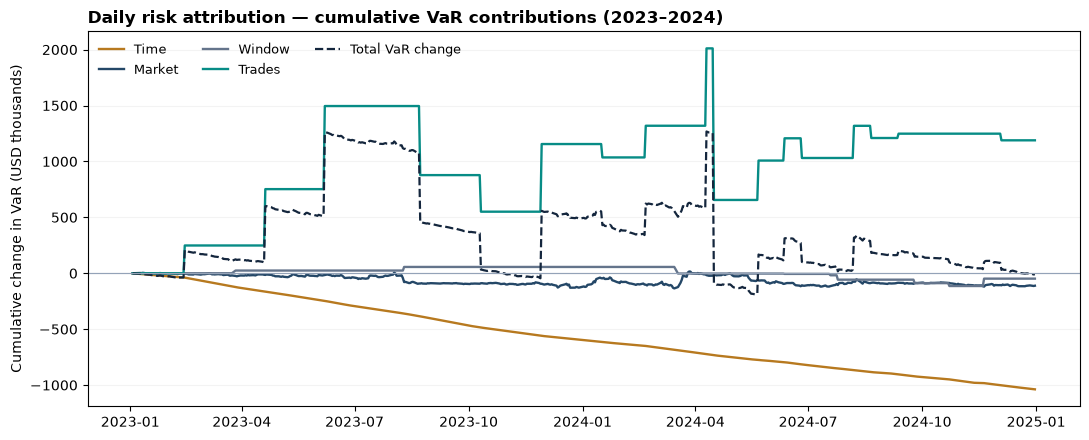

In [9]:
fig, ax = plt.subplots(figsize=(11, 4.5))
cumulative = vr[["time", "market", "window", "trades"]].cumsum() / 1000
palette = {
    "time": "#B7791F",
    "market": "#244767",
    "window": "#64748B",
    "trades": "#078C86",
}
for driver, color in palette.items():
    ax.plot(cumulative.index, cumulative[driver], label=driver.title(), color=color, lw=1.7)
ax.plot(
    vr.index,
    (vr["end"] - vr["start"].iloc[0]) / 1000,
    color="#14263D", lw=1.6, ls="--", label="Total VaR change",
)
ax.axhline(0, color="#94A3B8", lw=0.85)
ax.set_title("Daily risk attribution — cumulative VaR contributions (2023–2024)", loc="left", weight="bold")
ax.set_ylabel("Cumulative change in VaR (USD thousands)")
ax.grid(axis="y", alpha=0.15)
ax.set_axisbelow(True)
ax.legend(frameon=False, ncol=3, fontsize=9)
fig.tight_layout()
plt.show()


## 07 · Investigation Cases

### Case A · 2024-12-31 — a routine end-of-year risk walk

Closing VaR rose by approximately **$1,879** compared with the previous report (**$937,426 → $939,306**). Curve repricing contributed **+$2,311**, partly offset by **−$431** from aging (display figures rounded separately). There were no Trades or Window contributions on this morning.

### Case B · 2024-11-20 — a meaningful historical-window effect

A **+$66,023** Window Roll contribution outweighed negative Time and Market contributions. This is a useful reminder that a VaR increase **does not necessarily imply a new trade or a same-day market shock**.

### Case C · 2024-04-16 — a ticket amendment requiring investigation

Ticket `T019` changes from **+$50m** face in `GOV_34` to **−$50m** face, effective on its later booking date. The correct net position change is **−$100m face**, because the new booking *replaces* the previous one. The Trades / Amendments step contributed **−$1,355,422 VaR** and **−$85,347/bp Net DV01** on that morning. This large modeled reduction should be investigated against the actual blotter; it is **not, by itself, proof of a booking error**.

The code below prints the complete morning walk for the selected examples. For deeper inspection, the Excel deliverable supports date-based drilldown across all 518 mornings.


In [10]:
def show_morning(day):
    date = pd.Timestamp(day)
    d, v = dv.loc[date], vr.loc[date]
    rows = [
        ("Opening", d["start"], v["start"]),
        ("Time / Aging", d["time"], v["time"]),
        ("Market / Curve", d["market"], v["market"]),
        ("Window Roll", float("nan"), v["window"]),
        ("Trades / Amendments", d["trades"], v["trades"]),
        ("Closing", d["end"], v["end"]),
    ]
    frame = pd.DataFrame(rows, columns=["Step", "Net DV01 (USD/bp)", "99% VaR (USD)"])
    print(f"RISK WALK  |  {date:%Y-%m-%d}")
    display(frame.set_index("Step").round(0))

show_morning("2024-12-31")
show_morning("2024-11-20")
show_morning("2024-04-16")


RISK WALK  |  2024-12-31


,Net DV01 (USD/bp),99% VaR (USD)
Step,,
Opening,47118.0,937426.0
Time / Aging,-83.0,-431.0
Market / Curve,200.0,2311.0
Window Roll,NaN,0.0
Trades / Amendments,0.0,0.0
Closing,47234.0,939306.0


RISK WALK  |  2024-11-20


,Net DV01 (USD/bp),99% VaR (USD)
Step,,
Opening,53676.0,984896.0
Time / Aging,-87.0,-443.0
Market / Curve,-397.0,-4129.0
Window Roll,NaN,66023.0
Trades / Amendments,0.0,0.0
Closing,53191.0,1046347.0


RISK WALK  |  2024-04-16


,Net DV01 (USD/bp),99% VaR (USD)
Step,,
Opening,124988.0,2202732.0
Time / Aging,-91.0,-1585.0
Market / Curve,544.0,9591.0
Window Roll,NaN,0.0
Trades / Amendments,-85347.0,-1355422.0
Closing,40094.0,855316.0


## 08 · Validation & Controls

The walk is only useful if it **reconciles every day**. Three independent checks accompany the model:

1. **Continuity:** yesterday's closing 11-vertex ladder must equal today's opening ladder, $L_{3,t-1}=L_{0,t}$.
2. **DV01 arithmetic:** $L_3-L_0$ must equal the sum of Time, Market and Trades changes at each tenor.
3. **VaR arithmetic:** $V_4-V_0$ must equal the sum of all four sequential contributions.

The checks use *full-precision* model numbers. Small residuals from floating-point arithmetic are expected; they are **not** independent evidence that the source blotter or yield curves are accurate.


In [11]:
# Model-level invariants (stronger than checking only rounded Excel totals).
chain_gap = float(np.max(np.abs(L3[REP[:-1]] - L0[REP[1:]])))
ladder_gap = float(np.max(np.abs(
    (L3[REP] - L0[REP])
    - ((L1[REP] - L0[REP]) + (L2[REP] - L1[REP]) + (L3[REP] - L2[REP]))
)))
var_gap = float(np.max(np.abs(
    (vr["end"] - vr["start"])
    - vr[["time", "market", "window", "trades"]].sum(axis=1)
)))

checks = pd.DataFrame([
    {"Control": "Previous close = today's open (11 tenors)", "Max residual": chain_gap, "Tolerance": 1e-6},
    {"Control": "DV01 4-state arithmetic", "Max residual": ladder_gap, "Tolerance": 1e-6},
    {"Control": "VaR 5-state arithmetic", "Max residual": var_gap, "Tolerance": 1e-6},
])
checks["Result"] = np.where(checks["Max residual"] <= checks["Tolerance"], "PASS", "CHECK")
display(checks)
assert (checks["Result"] == "PASS").all(), "Risk attribution reconciliation failed"


,Control,Max residual,Tolerance,Result
0,Previous close = today's open (11 tenors),0.000000e+00,0.000001,PASS
1,DV01 4-state arithmetic,1.421085e-14,0.000001,PASS
2,VaR 5-state arithmetic,0.000000e+00,0.000001,PASS


## 09 · Excel Reporting Delivery

### From analytics to an investigation workflow

The notebook is the **calculation layer**; C# / ClosedXML builds the **presentation and interaction layer**.

```text
Market Data + Amended Trade Blotter
                  |
                  v
         Python Risk Engine
        daily DV01 / VaR Walk
                  |
                  v
          task2_snapshot.json
                  |
                  v
        C# ClosedXML Generator
     DeskRiskAttribution_Task2_V2.cs
                  |
                  v
    Interactive Excel Risk Workbook
```

| Worksheet | User-facing function |
|:--|:--|
| **01 Attribution Overview** | High-level DV01/VaR drivers and report status |
| **02 Daily Walk** | Every morning's attributed risk moves with reconciliation checks |
| **03 Morning Drilldown** | Select report date; inspect the sequential risk bridge |
| **04 Annual Attribution** | Annual driver totals and key-rate tenor breakdown |
| **05 Methodology** | Definitions, assumptions and reporting conventions |
| **06 Movers & Waterfall** | Large VaR-move ranking and formula-based dynamic bridge |

**Technology decision:** the workbook uses Excel formulas, a date dropdown and internal navigation, without VBA macros. It is an **EOD analytical report**, not a live market-data feed.

### 09.1 Export the calculation snapshot

The first code cell builds two chart images in memory for the Excel layout. The second writes the structured JSON contract consumed by C#. Neither creates additional standalone PNG files.


In [12]:
import base64
import io
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# TASK 2 - EXCEL DATA EXPORT
# ==========================================

output_dir = PROJECT_ROOT / "Excel_Template_Output"
output_dir.mkdir(parents=True, exist_ok=True)

L0, L1, L2, L3 = L

m24 = np.flatnonzero(dv.index.year == 2024)
idx24 = REP[m24]

# Validate yesterday-to-today ladder continuity
chain_gap = float(
    np.max(np.abs(L3[REP[:-1]] - L0[REP[1:]]))
)

if chain_gap > 1e-6:
    raise ValueError("Daily ladder continuity failed")


def encode_chart(fig):
    buffer = io.BytesIO()
    fig.savefig(
        buffer, format="png", dpi=145,
        bbox_inches="tight", facecolor="white"
    )
    plt.close(fig)
    return base64.b64encode(buffer.getvalue()).decode("ascii")


# ==========================================
# CHART 1 - CUMULATIVE VaR ATTRIBUTION
# ==========================================

fig, ax = plt.subplots(figsize=(10, 3.55))

drivers = [
    ("time", "#B7791F", "Time / Aging"),
    ("market", "#244767", "Market"),
    ("window", "#64748B", "Window Roll"),
    ("trades", "#078C86", "Trades")
]

for field, color, label in drivers:
    ax.plot(
        vr.index,
        vr[field].cumsum() / 1000,
        label=label,
        color=color,
        linewidth=1.6
    )

ax.plot(
    vr.index,
    (vr.end - vr.start.iloc[0]) / 1000,
    color="#14263D",
    linestyle="--",
    linewidth=1.2,
    label="Total VaR Change"
)

ax.axhline(0, color="#94A3B8", linewidth=0.8)
ax.grid(axis="y", alpha=0.15)
ax.set_axisbelow(True)
ax.set_ylabel("Cumulative VaR change ($000)")
ax.legend(ncol=3, fontsize=8.5, frameon=False)
fig.tight_layout()

cumulative_chart = encode_chart(fig)


# ==========================================
# CHART 2 - 2024 KEY-RATE ATTRIBUTION
# ==========================================

steps24 = {
    "time": (L1[idx24] - L0[idx24]).sum(axis=0),
    "market": (L2[idx24] - L1[idx24]).sum(axis=0),
    "trades": (L3[idx24] - L2[idx24]).sum(axis=0)
}

fig, ax = plt.subplots(figsize=(10, 3.45))
x = np.arange(len(LAB))

for offset, field, color in [
    (-0.25, "time", "#B7791F"),
    (0, "market", "#244767"),
    (0.25, "trades", "#078C86")
]:
    ax.bar(
        x + offset,
        steps24[field] / 1000,
        width=0.25,
        label=field.capitalize(),
        color=color
    )

ax.set_xticks(x, LAB)
ax.axhline(0, color="#94A3B8", linewidth=0.8)
ax.grid(axis="y", alpha=0.15)
ax.set_axisbelow(True)
ax.set_ylabel("2024 change in key-rate DV01 ($000/bp)")
ax.legend(frameon=False, ncol=3)
fig.tight_layout()

ladder_chart = encode_chart(fig)


### 09.2 Serialize daily, annual and tenor attribution

The JSON snapshot is intentionally explicit: **one entry per reporting date**, annual totals, 2024 tenor-level contributions, reconciliation continuity, and images. This keeps the C# generator focused on UI/report construction rather than reimplementing the Python risk math.


In [13]:
# ==========================================
# DAILY RISK ATTRIBUTION
# ==========================================

daily = []

for date in dv.index:
    a = dv.loc[date]
    b = vr.loc[date]

    daily.append({
        "date": date.strftime("%Y-%m-%d"),
        "dvStart": float(a.start),
        "dvTime": float(a.time),
        "dvMarket": float(a.market),
        "dvTrades": float(a.trades),
        "dvEnd": float(a.end),
        "varStart": float(b.start),
        "varTime": float(b.time),
        "varMarket": float(b.market),
        "varWindow": float(b.window),
        "varTrades": float(b.trades),
        "varEnd": float(b.end)
    })


# ==========================================
# ANNUAL RISK ATTRIBUTION
# ==========================================

years = []

for year in (2023, 2024):
    a = dv[dv.index.year == year]
    b = vr[vr.index.year == year]

    years.append({
        "year": year,
        "reportDays": len(a),
        "dvStart": float(a.start.iloc[0]),
        "dvTime": float(a.time.sum()),
        "dvMarket": float(a.market.sum()),
        "dvTrades": float(a.trades.sum()),
        "dvEnd": float(a.end.iloc[-1]),
        "varStart": float(b.start.iloc[0]),
        "varTime": float(b.time.sum()),
        "varMarket": float(b.market.sum()),
        "varWindow": float(b.window.sum()),
        "varTrades": float(b.trades.sum()),
        "varEnd": float(b.end.iloc[-1])
    })


# ==========================================
# 2024 LADDER BY TENOR
# ==========================================

ladder2024 = []

for k, tenor in enumerate(LAB):
    ladder2024.append({
        "tenor": tenor,
        "start": float(L0[idx24[0], k]),
        "time": float(steps24["time"][k]),
        "market": float(steps24["market"][k]),
        "trades": float(steps24["trades"][k]),
        "end": float(L3[idx24[-1], k])
    })


# ==========================================
# EXPORT JSON FOR C#
# ==========================================

payload = {
    "asOf": DATES[REP[-1]].strftime("%Y-%m-%d"),
    "chainMaxGap": chain_gap,
    "daily": daily,
    "years": years,
    "ladder2024": ladder2024,
    "cumulativeChart": cumulative_chart,
    "ladderChart": ladder_chart
}

snapshot = output_dir / "task2_snapshot.json"

snapshot.write_text(
    json.dumps(payload, allow_nan=False),
    encoding="utf-8"
)

print("Task 2 Snapshot:", snapshot.relative_to(PROJECT_ROOT))
print("Report Days:", len(daily))
print("2024 Closing VaR:", f"${years[-1]['varEnd']:,.0f}")
print("Max Chain Gap:", chain_gap)


Task 2 Snapshot: Excel_Template_Output\task2_snapshot.json
Report Days: 518
2024 Closing VaR: $939,306
Max Chain Gap: 0.0


### 09.3 Generate the interactive workbook with C#

The C# source is stored in `Excel_Template_Design/`; generated JSON and spreadsheets are written to `Excel_Template_Output/`. On Windows, install the **.NET 10 SDK** and allow package restore for `ClosedXML 0.105.1` before running this optional publishing step.

> **Portability note:** Python paths are project-relative (or controlled by `RAD_RISK_ROOT`). If moving to another machine, also configure the output path inside the existing C# generator; that file may still contain a workstation-specific location.


In [15]:
import subprocess
import shutil

CS_FILE = PROJECT_ROOT / "Excel_Template_Design" / "DeskRiskAttribution_Task2_V2.cs"

if not CS_FILE.is_file():
    print(f"Excel publishing skipped: C# source not found at {CS_FILE}")
elif shutil.which("dotnet") is None:
    print("Excel publishing skipped: .NET 10 SDK is not installed in this environment.")
else:
    result = subprocess.run(
        ["dotnet", "run", "--file", str(CS_FILE)],
        cwd=PROJECT_ROOT,
        capture_output=True,
        text=True,
        encoding="utf-8",
        errors="replace",
    )
    print("Exit Code:", result.returncode)
    print(result.stdout)
    if result.stderr.strip():
        print(result.stderr)
    if result.returncode != 0:
        raise RuntimeError("Task 2 C# Excel generation failed")


Exit Code: 0
SUCCESS / TASK 2 V2 INTERACTIVE ATTRIBUTION
Excel: C:\Users\franklinpeng\Desktop\RDA Risk test\Excel_Template_Output\RatesDesk_RiskAttribution_Task2_V2_2024-12-31.xlsx
Report days: 518
Interactive date dropdown, VaR bridge, top 10 movers, reconciliation flags ready.
2024 Closing DV01: +47,234 USD/bp
2024 Closing VaR: $939,306
Max previous-day ladder gap: 0



## 10 · Interpretation, Limitations & Next Steps

### What the results establish

- A reproducible, reconciled **daily risk attribution** exists for **518 reporting mornings**.
- The 2024 VaR change is explained by **Time, Market, Window and Trades** contributions, rather than one opaque end-of-day figure.
- The model preserves the **11-tenor Key-Rate DV01** view and explicitly distinguishes risk from parallel versus curve-shape changes.
- The report converts model output into a **date-selectable risk review workflow** with investigation and control surfaces.

### Boundaries that matter

- **Simulated bond book** and EOD market data only; no live pricing or production controls.
- Historical VaR uses **first-order DV01 shocks**, not full cash-flow repricing or convexity adjustment.
- The **500-day / fifth-worst** estimator depends on the sample, observation count and scenario window.
- **Sequential attribution is order-dependent**. Other decomposition orders can redistribute contributions while keeping closing VaR fixed.
- `PASS` means the **accounting identity balances**; it does *not* certify source completeness, market-data quality or booking correctness.
- Credit spreads, funding, liquidity, transaction costs and real-time position updates are beyond the scope.

### Next module · Task 03 — P&L Explain

Extend the risk monitoring stack with **Carry**, **Predicted Market P&L**, **Reported P&L**, **Unexplained P&L** and **noise-adjusted exception thresholds**, then connect exception evidence to the investigative workflow.

---

**Portfolio framing:** *Python quantitative risk engine → reconciled analytical data contract → C# / Excel front-office reporting interface.*  
**Source credit:** [RiskHub — Fixed Income Risk Dashboard](https://riskhub.org/python-labs/fixed-income-risk-dashboard) · Simulated educational exercise, independently extended with reporting and controls.
